In [2]:
#Import the necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
#To suppress all warnings
import warnings
warnings.filterwarnings('ignore')

In [13]:
# the 1 task

df = sns.load_dataset("titanic")
df.head(10)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False


In [17]:
print(df.isnull().sum())

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [19]:
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')

In [20]:
df["embarked"].unique()

array(['S', 'C', 'Q', nan], dtype=object)

In [27]:
# the 2 task

df["embarked"].fillna(df["embarked"].mode(), inplace = True)

In [44]:
df["sex"] = df["sex"].astype("category")
df["class"] = df["class"].astype("category")
df[["sex", "class"]].dtypes

sex      category
class    category
dtype: object

In [31]:
df["family_size"] = df["sibsp"] + df["parch"] + 1

In [33]:
df_clean = df.drop(columns=["deck"])

p99 = df_clean["fare"].quantile(0.99)

df_clean["fare_capped"] = df_clean["fare"].clip(upper=p99)

print(f"Fare values above {p99:.2f} were capped at the 99th percentile.")


Fare values above 249.01 were capped at the 99th percentile.


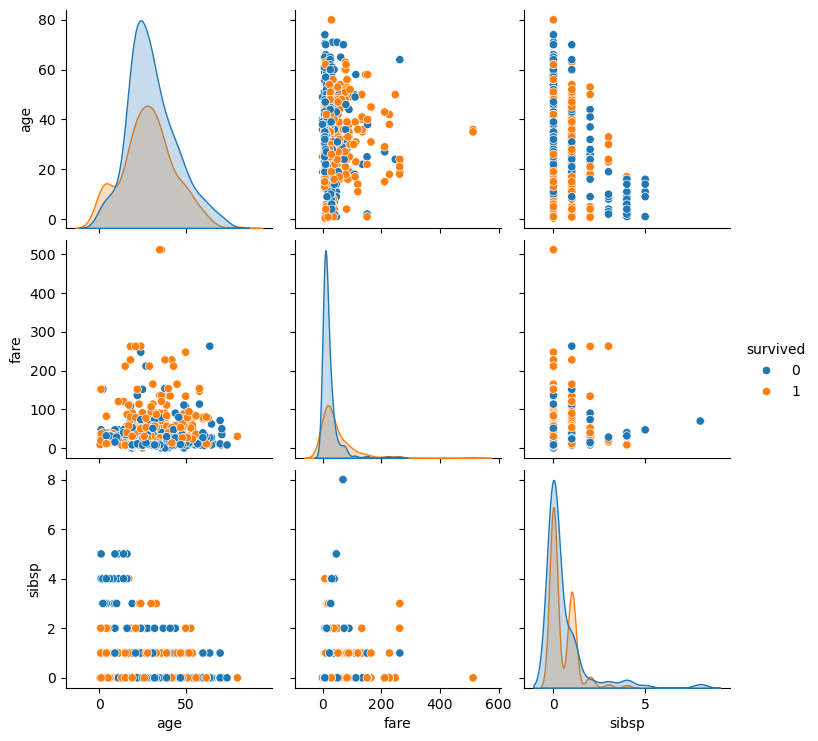

In [35]:
# yhe 3 task

sns.pairplot(df_clean, vars=['age', 'fare', 'sibsp'],
hue='survived', diag_kind='kde')
plt.show()

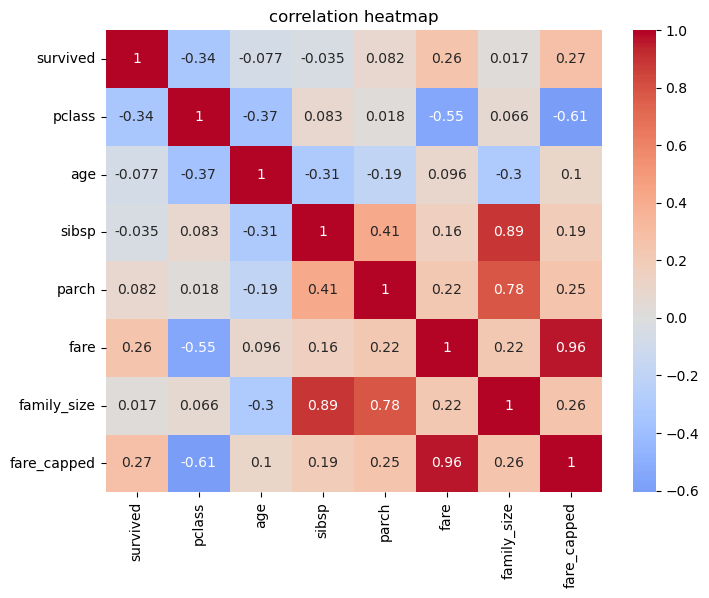

In [36]:
plt.figure(figsize = (8, 6))
numeric_cols = df_clean.select_dtypes(include=np.number).columns
sns.heatmap(df_clean[numeric_cols].corr(), annot = True, cmap = "coolwarm", center = 0)
plt.title("correlation heatmap")
plt.show()

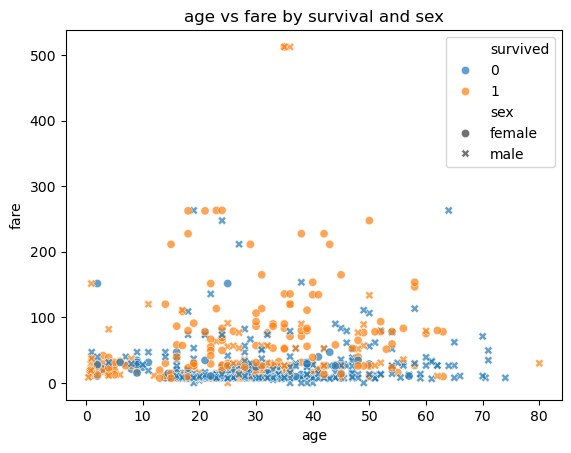

In [37]:
sns.scatterplot(x = "age", y = "fare", hue = "survived", style = "sex", alpha = 0.7, data = df_clean)
plt.title("age vs fare by survival and sex")
plt.show()

Text(0.5, 1.0, 'age distribution')

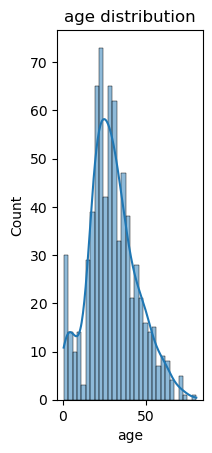

In [38]:
plt.subplot(1, 3, 1)
sns.histplot(df_clean["age"], kde = True, bins = 30)
plt.title("age distribution")